# 02 — Data check for `build_dataset`

*26 Nov 2026.* Checks of the facts `build_dataset` depends on, before its design decisions (D1–D12) are made.
Each check has a short description, the code, and a **Findings** cell with what the numbers show and the decision
they inform. A summary of all findings and the open questions is at the end.

**Memory.** The machine has little free RAM, so `met_forecast.parquet` is never loaded whole: only key columns,
read in batches, and weather columns for three parks only. Park names are read dictionary-encoded.

**Already known from `scratch/1_audit.ipynb` (not recomputed):**
- Forecast: 2020-02-15 12Z → 2025-03-24 09Z, 1,798 issues (1,282 at 12Z, 516 at 09Z; first 09Z issue 2023-10-01),
  61 parks, max lt 61 h (12Z) / 64 h (09Z), lt step 1 h, no NaNs, no missing rows, 67 days without an issue.
- Power (train): 2020-01-01 → 2025-04-03 08Z, 3 gaps (54 h), 13 NaNs.
- Nowcast (train): 2020-01-01 → 2025-03-31; the "61 gaps" all at 2024-08-20 22Z (checked per park in C6).
- Eval: power 2025-05-31 → 2025-10-06, nowcast 2025-06-02 → 2025-10-03.

**Folds (F26 v4), assigned by issue date D in local time:** train Jan 2020 – Mar 2023, val Apr 2023 – Mar 2024,
test Apr 2024 – Mar 2025.

In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from windai.paths import get_data_root, list_files
from windai.data.dataset_loader import load_power, load_parks, STORED_TO_CANONICAL_NAMES

ROOT = get_data_root()
TZ = "Europe/Oslo"
ZONES = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
# Fold boundaries as local dates: [start, end)
FOLDS = {"train": ("2020-01-01", "2023-04-01"), "val": ("2023-04-01", "2024-04-01"), "test": ("2024-04-01", "2025-04-01")}
FOLD_BOUNDS = {k: (pd.Timestamp(a).date(), pd.Timestamp(b).date()) for k, (a, b) in FOLDS.items()}


def fold_of(local_dates):
    out = pd.Series(pd.NA, index=range(len(local_dates)), dtype="object")
    d = pd.Series(local_dates)
    for name, (a, b) in FOLD_BOUNDS.items():
        out[(d >= a) & (d < b)] = name
    return out.to_numpy()


# The machine has little free RAM, so met_forecast is read in small batches and filtered batch by batch.
# Park names are read dictionary-encoded (an integer code per row instead of a string).
import pyarrow as pa
import pyarrow.compute as pc

def stream_forecast(columns, sids=None, min_lt=None, batch_size=200_000):
    f = pq.ParquetFile(ROOT / "met_forecast.parquet")
    parts = []
    for b in f.iter_batches(batch_size=batch_size, columns=columns):
        mask = None
        if sids is not None:
            mask = pc.is_in(b.column("sid"), value_set=pa.array(sids))
        if min_lt is not None:
            m2 = pc.greater_equal(b.column("lt"), min_lt)
            mask = m2 if mask is None else pc.and_(mask, m2)
        parts.append(b.filter(mask) if mask is not None else b)
    return pa.Table.from_batches(parts)

## C1 — Lead-time coverage of D+2 (±1 h)
For each issue: the UTC target hours of D+2 00:00–23:00 local (23 or 25 on DST days), the lead times they need, and
whether the issue's lt range also covers one hour before and after (for wind at t−1 and t+1).

In [2]:
keys = pq.read_table(ROOT / "met_forecast.parquet", columns=["time_ref", "lt"])
agg = keys.group_by("time_ref").aggregate([("lt", "min"), ("lt", "max"), ("lt", "count_distinct")]).to_pandas()
del keys
agg.columns = ["time_ref", "lt_min", "lt_max", "n_lt"]
issues = agg.assign(time_ref=agg["time_ref"].dt.tz_localize("UTC")).sort_values("time_ref").reset_index(drop=True)
issues["regime"] = issues["time_ref"].dt.hour.map({9: "09Z", 12: "12Z"})
issues["D"] = issues["time_ref"].dt.tz_convert(TZ).dt.date

def needed_lts(row):
    start = pd.Timestamp(row.D, tz=TZ) + pd.DateOffset(days=2)          # local midnight of D+2 (calendar days)
    hours = pd.date_range(start, start + pd.DateOffset(days=1), freq="h", inclusive="left")  # 23/24/25 hours
    lts = ((hours.tz_convert("UTC") - row.time_ref) / pd.Timedelta(hours=1)).astype(int)
    return lts.min(), lts.max(), len(hours)

issues[["need_min", "need_max", "n_target_hours"]] = issues.apply(needed_lts, axis=1, result_type="expand")
issues["covers"] = issues["need_max"] <= issues["lt_max"]
issues["covers_pm1"] = (issues["need_max"] + 1 <= issues["lt_max"]) & (issues["need_min"] - 1 >= issues["lt_min"])
issues["lt_gapless"] = issues["n_lt"] == issues["lt_max"] - issues["lt_min"] + 1

print(issues.groupby("regime").agg(n=("time_ref", "size"), lt_max_min=("lt_max", "min"), lt_max_max=("lt_max", "max"),
                                   need_min=("need_min", "min"), need_max=("need_max", "max"),
                                   covers=("covers", "mean"), covers_pm1=("covers_pm1", "mean"),
                                   lt_gapless=("lt_gapless", "mean")))
print("\nTarget hours per issue:", issues["n_target_hours"].value_counts().to_dict())
print("\nIssues that don't cover D+2 ±1 h:")
print(issues.loc[~issues["covers_pm1"], ["time_ref", "regime", "lt_min", "lt_max", "need_min", "need_max"]])

           n  lt_max_min  lt_max_max  need_min  need_max  covers  covers_pm1  \
regime                                                                         
09Z      516          64          64        37        61  1.0000      1.0000   
12Z     1282           4          61        34        58  0.9922      0.9922   

        lt_gapless  
regime              
09Z            1.0  
12Z            1.0  

Target hours per issue: {24: 1788, 23: 5, 25: 5}

Issues that don't cover D+2 ±1 h:
                      time_ref regime  lt_min  lt_max  need_min  need_max
90   2020-05-18 12:00:00+00:00    12Z       0      11        34        57
273  2020-11-21 12:00:00+00:00    12Z       0      55        35        58
381  2021-03-11 12:00:00+00:00    12Z       0      18        35        58
408  2021-04-08 12:00:00+00:00    12Z       0      26        34        57
447  2021-05-17 12:00:00+00:00    12Z       0      55        34        57
518  2021-07-30 12:00:00+00:00    12Z       0       6        34   

In [3]:
# Spot check: one winter and one summer issue per regime
for ts in ["2021-01-15 12:00", "2021-07-15 12:00", "2024-01-15 09:00", "2024-07-15 09:00"]:
    row = issues.loc[issues["time_ref"] == pd.Timestamp(ts, tz="UTC")]
    print(ts, row[["need_min", "need_max", "n_target_hours", "lt_max"]].to_dict("records"))

2021-01-15 12:00 [{'need_min': 35, 'need_max': 58, 'n_target_hours': 24, 'lt_max': 61}]
2021-07-15 12:00 [{'need_min': 34, 'need_max': 57, 'n_target_hours': 24, 'lt_max': 61}]
2024-01-15 09:00 [{'need_min': 38, 'need_max': 61, 'n_target_hours': 24, 'lt_max': 64}]
2024-07-15 09:00 [{'need_min': 37, 'need_max': 60, 'n_target_hours': 24, 'lt_max': 64}]


### Findings (C1)
- **Lead times needed for D+2 00–23 local:** 09Z issues need lt 37–61 (37–60 in summer, 38–61 in winter); 12Z
  issues need lt 34–58. With wind at t±1: 36–62 and 33–59. The spot checks above match this arithmetic.
- **All 516 09Z issues cover D+2 ±1 h** (every one reaches lt 64).
- **1,272 of the 1,282 12Z issues cover it. 10 are truncated** (max lt between 4 and 55, listed above). These are
  shortened MEPS runs, not holes: every issue has every lead time from 0 to its own maximum (`lt_gapless` = 1).
- **DST works:** 5 issues have 23 target hours and 5 have 25 (a clock change on D+2).
- **Consequence:** Weber's "about 60 h" concern doesn't apply to this dataset. Drop the 10 truncated issues
  (0.8 % of the 12Z issues), and put these lead times into F26 §2.

→ informs **D3, D10, D11** and the lead-time text in F26 §2.

## C2 — The F26 date folds
Per fold: issues, regime split, days without an issue, and target-time range. "Crossing" issues have targets
(D+2) in the next fold; those are the rows to purge from a training set that ends at the boundary.

In [4]:
issues["fold"] = fold_of(issues["D"])
issues["target_fold"] = fold_of([d + pd.Timedelta(days=2) for d in issues["D"]])
issues["first_target"] = [pd.Timestamp(d, tz=TZ) + pd.DateOffset(days=2) for d in issues["D"]]
issues["last_target"] = [t + pd.DateOffset(days=1) - pd.Timedelta(hours=1) for t in issues["first_target"]]

rows = []
for name, (a, b) in FOLD_BOUNDS.items():
    f = issues.loc[issues["fold"] == name]
    span = pd.date_range(max(a, f["D"].min()), min(b - pd.Timedelta(days=1), f["D"].max()), freq="D").date
    rows.append({"fold": name, "issues": len(f), "12Z": (f["regime"] == "12Z").sum(), "09Z": (f["regime"] == "09Z").sum(),
                 "first_issue": f["D"].min(), "last_issue": f["D"].max(), "days_without_issue": len(set(span) - set(f["D"])),
                 "crossing": (f["target_fold"] != name).sum(),
                 "first_target": f["first_target"].min(), "last_target": f["last_target"].max()})
folds_table = pd.DataFrame(rows).set_index("fold")
print(folds_table.to_string())
print("\nIssues outside every fold:", issues["fold"].isna().sum())
print("train + val + test =", folds_table["issues"].sum(), "of", len(issues))

power = load_power()
print("\nLast power hour:", power.index.max(), "| last test target (UTC):", issues["last_target"].max().tz_convert("UTC"))

       issues   12Z  09Z first_issue  last_issue  days_without_issue  crossing              first_target               last_target
fold                                                                                                                              
train    1104  1104    0  2020-02-15  2023-03-31                  37         2 2020-02-17 00:00:00+01:00 2023-04-02 23:00:00+02:00
val       357   178  179  2023-04-01  2024-03-31                   9         2 2023-04-03 00:00:00+02:00 2024-04-02 23:00:00+02:00
test      337     0  337  2024-04-01  2025-03-24                  21         0 2024-04-03 00:00:00+02:00 2025-03-26 23:00:00+01:00

Issues outside every fold: 0
train + val + test = 1798 of 1798

Last power hour: 2025-04-03 08:00:00+00:00 | last test target (UTC): 2025-03-26 22:00:00+00:00


### Findings (C2)
| fold | issues | 12Z / 09Z | first – last issue | days without an issue |
|---|---|---|---|---|
| train | 1,104 | 1,104 / 0 | 2020-02-15 – 2023-03-31 | 37 |
| val | 357 | 178 / 179 | 2023-04-01 – 2024-03-31 | 9 |
| test | 337 | 0 / 337 | 2024-04-01 – 2025-03-24 | 21 (incl. the 7-day gap in Aug 2024) |

- Every issue falls in exactly one fold (1,798 in total).
- **2 issues per boundary** (30 and 31 Mar) have targets in the next fold. They must be purged when the earlier
  fold is used for training, otherwise training sees power observed after the next fold has started.
- Power runs to 2025-04-03, past the last test target (2025-03-26 22Z), so every test row has an observation.
- The test fold holds 337 issues, not 365, because the forecasts stop on 2025-03-24 and some days have none.
- **Consequence:** assign folds by the local issue date D, and purge the 2 crossing issues at each boundary.

→ informs **D2** (fold assignment and purging).

## C3 — Parks metadata: duplicates and capacity over time

In [5]:
parks = load_parks()
print(len(parks), "rows,", parks["substation_name"].nunique(), "unique names,", parks["eic_code"].nunique(), "unique eic_codes")
dup_names = parks[parks["substation_name"].duplicated(keep=False)].sort_values(["substation_name", "prod_start_new"])
print("\nRows with a duplicated name:")
print(dup_names.to_string())
dup_eic = parks[parks["eic_code"].duplicated(keep=False)]
print("\nRows with a duplicated eic_code:", len(dup_eic))
if len(dup_eic):
    print(dup_eic.sort_values("eic_code").to_string())

76 rows, 65 unique names, 75 unique eic_codes

Rows with a duplicated name:
   bidding_area     substation_name  operating_power_max            prod_start_new          eic_code
6    ELSPOT NO2   Bjerk_VK Vindpark                301.0 2020-01-01 00:00:00+00:00  50WP000000017693
7    ELSPOT NO2   Bjerk_VK Vindpark                301.0 2020-01-01 00:00:00+00:00  50WP00000001721V
42   ELSPOT NO3               Hitra                148.8 2020-01-08 12:00:00+00:00  50WP00000001993Z
43   ELSPOT NO3               Hitra                148.8 2020-01-08 12:00:00+00:00  50WP00000000269S
67   ELSPOT NO4  Kvitfjell vindpark                197.4 2020-01-23 11:00:00+00:00  50WP00000001809H
68   ELSPOT NO4  Kvitfjell vindpark                197.4 2020-01-23 11:00:00+00:00  50WP00000001828D
15   ELSPOT NO2          Måkaknuten                124.7 2020-05-31 22:00:00+00:00  50WP00000002079N
16   ELSPOT NO2          Måkaknuten                124.7 2020-05-31 22:00:00+00:00  50WP00000002083W
49   ELSPOT NO3

In [6]:
forecast_sids = set()
for b in pq.ParquetFile(ROOT / "met_forecast.parquet").iter_batches(batch_size=500_000, columns=["sid"]):
    forecast_sids.update(pc.unique(b.column("sid")).to_pylist())
nowcast_names = {STORED_TO_CANONICAL_NAMES.get(n, n)
                 for n in pq.read_table(ROOT / "met_nowcast.parquet", columns=["windpark"], read_dictionary=["windpark"]).to_pandas(ignore_metadata=True)["windpark"].cat.categories}
meta_names = set(parks["substation_name"])
print("metadata, not in forecast:", ascii(sorted(meta_names - forecast_sids)))
print("forecast, not in metadata:", ascii(sorted(forecast_sids - meta_names)))
print("forecast, not in nowcast: ", ascii(sorted(forecast_sids - nowcast_names)))
print("nowcast, not in forecast: ", ascii(sorted(nowcast_names - forecast_sids)))

metadata, not in forecast: ['Hinn\xf8y', 'H\xe5vik', 'Orkdal', 'Ramslandsv\xe5gen']
forecast, not in metadata: []
forecast, not in nowcast:  []
nowcast, not in forecast:  []


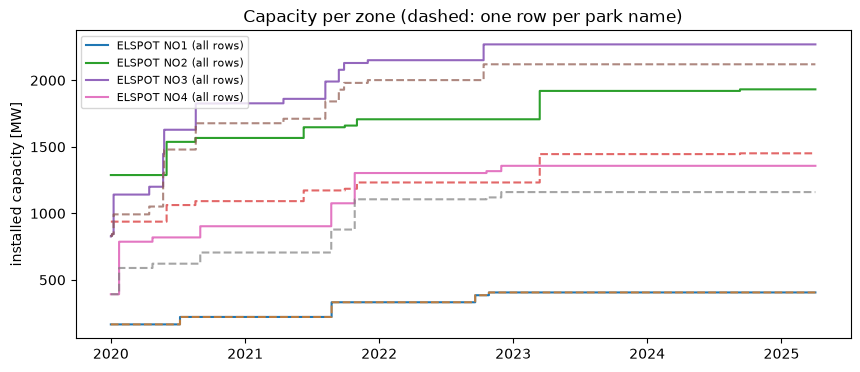

            all rows  per eic_code  per name
ELSPOT NO1     405.7         405.7     405.7
ELSPOT NO2    1932.1        1932.1    1451.3
ELSPOT NO3    2270.0        2270.0    2120.4
ELSPOT NO4    1357.4        1130.0    1160.0


In [7]:
# Installed capacity per zone over time, all metadata rows vs one row per eic_code
hourly = power.index
def capacity_hourly(df):
    out = pd.DataFrame(index=hourly)
    for z in ZONES:
        g = df.loc[df["bidding_area"] == z].sort_values("prod_start_new")
        steps = g.groupby("prod_start_new")["operating_power_max"].sum().cumsum()
        out[z] = steps.reindex(hourly.union(steps.index)).ffill().reindex(hourly).fillna(0.0)
    return out

cap_all = capacity_hourly(parks)
cap_eic = capacity_hourly(parks.drop_duplicates("eic_code"))
cap_name = capacity_hourly(parks.drop_duplicates("substation_name"))
fig, ax = plt.subplots(figsize=(10, 4))
for z in ZONES:
    ax.step(cap_all.index, cap_all[z], where="post", label=f"{z} (all rows)")
    ax.step(cap_name.index, cap_name[z], where="post", ls="--", alpha=0.7)
ax.set_ylabel("installed capacity [MW]"); ax.legend(fontsize=8); ax.set_title("Capacity per zone (dashed: one row per park name)")
plt.show()
print(pd.DataFrame({"all rows": cap_all.iloc[-1], "per eic_code": cap_eic.iloc[-1], "per name": cap_name.iloc[-1]}))

### Findings (C3)
- **76 rows, 65 park names, 75 EIC codes.**
- **A duplicated name is one park listed under several EIC codes.** Every row repeats the same capacity and start
  date: Stokkeland 5 × 12.3 MW, Bjerk 2 × 301 MW, Hitra 2 × 148.8, Kvitfjell 2 × 197.4, Måkaknuten 2 × 124.7,
  Skudeneshavn 2 × 5.9, Orkdal 3 × 0.4. The values are identical rather than split, which fits several EIC
  registrations of one park (for example units or metering points). Summing them double counts. C4 confirms this
  independently.
- **The one shared EIC code is two phases of one park:** Øyfjell1 (172.6 MW, Aug 2021) and Øyfjell2 (227.4 MW,
  Oct 2021). They have different names, capacities and start dates, so deduplicating by EIC code would drop a phase.
- **So deduplicate by `substation_name`.** Final installed capacity:

  | zone | all rows | per EIC code | **per name** |
  |---|---|---|---|
  | NO1 | 405.7 | 405.7 | **405.7** |
  | NO2 | 1,932.1 | 1,932.1 | **1,451.3** |
  | NO3 | 2,270.0 | 2,270.0 | **2,120.4** |
  | NO4 | 1,357.4 | 1,130.0 | **1,160.0** |

- **Name sets:** the forecast and nowcast have exactly the same 61 parks (after the Tonst/Sørfj mapping), and all
  of them are in the metadata. Hinnøy, Håvik, Orkdal and Ramslandsvågen are in the metadata only.
- **Consequence:** zone capacity = the sum over unique park names with `prod_start_new` ≤ t. That includes the 4
  parks without weather, because their production is part of the zone totals.

→ informs **D1, D5**.

## C4 — Capacity factor
CF = zone power / installed capacity (all metadata rows; compare with per-`eic_code` in the last cell). Hours with
CF > 1 point to a capacity error or a missing park; hours at exactly 0 are the lower point mass.

In [8]:
def cf_summary(cap):
    cf = power[ZONES] / cap[ZONES].where(cap[ZONES] > 0)
    rows = []
    for z in ZONES:
        s = cf[z].dropna()
        by_year = s.groupby(s.index.year)
        rows.append(pd.DataFrame({"mean": by_year.mean(), "p99": by_year.quantile(0.99), "max": by_year.max(),
                                  "share_0": by_year.apply(lambda x: (x <= 0).mean()),
                                  "share_gt1": by_year.apply(lambda x: (x > 1).mean())}).assign(zone=z))
    return cf, pd.concat(rows).reset_index(names="year").set_index(["zone", "year"])

cf, cf_table = cf_summary(cap_all)
print(cf_table.round(3).to_string())

                  mean    p99    max  share_0  share_gt1
zone       year                                         
ELSPOT NO1 2020  0.322  0.948  0.976    0.026        0.0
           2021  0.232  0.683  0.722    0.017        0.0
           2022  0.268  0.831  0.882    0.001        0.0
           2023  0.263  0.877  0.933    0.000        0.0
           2024  0.269  0.854  0.918    0.000        0.0
           2025  0.386  0.922  0.935    0.000        0.0
ELSPOT NO2 2020  0.231  0.582  0.615    0.000        0.0
           2021  0.223  0.617  0.653    0.000        0.0
           2022  0.273  0.645  0.675    0.000        0.0
           2023  0.258  0.673  0.702    0.000        0.0
           2024  0.268  0.668  0.703    0.000        0.0
           2025  0.234  0.660  0.676    0.000        0.0
ELSPOT NO3 2020  0.290  0.742  0.819    0.000        0.0
           2021  0.290  0.780  0.836    0.000        0.0
           2022  0.335  0.781  0.835    0.000        0.0
           2023  0.289  0.786  

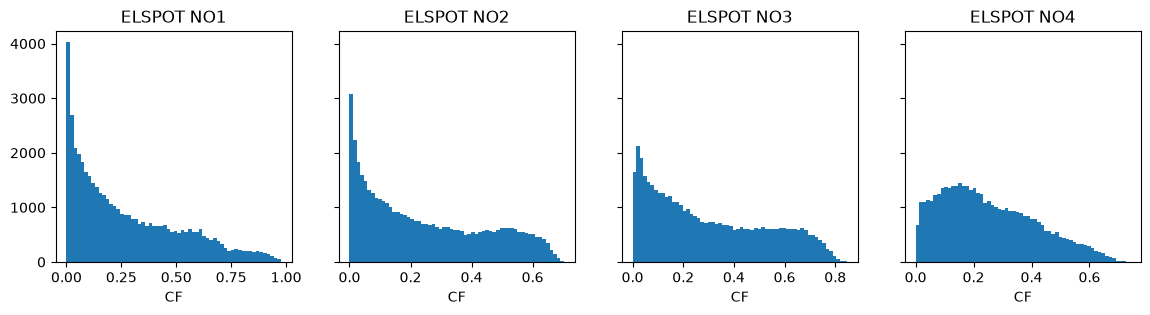

per eic_code: max CF per zone and year
zone  ELSPOT NO1  ELSPOT NO2  ELSPOT NO3  ELSPOT NO4
year                                                
2020        0.98        0.62        0.82        0.68
2021        0.72        0.65        0.84        0.68
2022        0.88        0.67        0.83        0.88
2023        0.93        0.70        0.85        0.89
2024        0.92        0.70        0.81        0.86
2025        0.93        0.68        0.77        0.85

per park name: max CF per zone and year
zone  ELSPOT NO1  ELSPOT NO2  ELSPOT NO3  ELSPOT NO4
year                                                
2020        0.98        0.88        0.88        0.87
2021        0.72        0.94        0.91        0.86
2022        0.88        0.93        0.89        0.85
2023        0.93        0.94        0.91        0.87
2024        0.92        0.93        0.87        0.84
2025        0.93        0.90        0.83        0.82

per park name: full table
                  mean    p99    max  share_0

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, z in zip(axes, ZONES):
    ax.hist(cf[z].dropna().clip(upper=1.2), bins=60)
    ax.set_title(z); ax.set_xlabel("CF")
plt.show()
for label, cap in [("per eic_code", cap_eic), ("per park name", cap_name)]:
    _, t = cf_summary(cap)
    print(f"{label}: max CF per zone and year")
    print(t["max"].unstack(0).round(2))
    print()
_, cf_table_name = cf_summary(cap_name)
print("per park name: full table")
print(cf_table_name.round(3).to_string())

### Findings (C4)
- **Per-name capacity gives plausible capacity factors.** Max CF is 0.82–0.98 for every zone and year, and the
  99th percentile is 0.68–0.95. With all rows, NO2 never exceeds 0.62–0.70 in any year, well below the other
  zones. That supports the deduplication in C3.
- **CF never exceeds 1**, with any of the three capacity variants.
- **There's almost no point mass at 0 at zone level.** Exactly-zero hours occur only in NO1 in 2020–21
  (2.6 % / 1.7 %) and NO4 in 2020 (0.3 %), when those zones had few parks. Summing over parks removes it.
- **Mean CF varies by year** (0.27–0.39), from weather and from which parks exist. That's a first look at the
  stationarity question (F26 Q4), but it only becomes interpretable with the EMOS residuals.
- **Consequence:** a censored normal on [0, 1] is still a valid choice for EMOS, but the censoring rarely binds at
  zone level. That's worth stating in the report, and it makes the PIT randomisation matter less than expected.

→ informs **D1** and the EMOS distribution (censored normal on [0, 1]).

## C5 — Missing power mapped onto the folds

In [10]:
full = pd.date_range(power.index.min(), power.index.max(), freq="h")
missing = full.difference(power.index)
nan_rows = power.index[power[ZONES].isna().any(axis=1)]
bad = pd.DataFrame({"time": missing.append(nan_rows), "kind": ["missing"] * len(missing) + ["NaN"] * len(nan_rows)})
bad["fold"] = fold_of(bad["time"].dt.tz_convert(TZ).dt.date)  # fold of the target day
print(bad.groupby(["fold", "kind"], dropna=False).size())
print(bad.loc[bad["fold"].isin(["val", "test"])].to_string())

fold   kind   
test   NaN         1
train  NaN        12
       missing    54
dtype: int64
                        time kind  fold
66 2024-11-21 13:00:00+00:00  NaN  test


### Findings (C5)
- All 54 missing hours (3 gaps) and 12 of the 13 NaNs are in the **train** fold.
- **Val is complete.** **Test has one NaN:** 2024-11-21 13Z, NO2.
- **Consequence:** drop target hours without an observation (no imputation). That costs nothing noticeable.

→ informs **D10**.

## C6 — Nowcast gaps per park and coverage per year

In [11]:
nc = pq.read_table(ROOT / "met_nowcast.parquet", columns=["windpark", "time"], read_dictionary=["windpark"]).to_pandas(ignore_metadata=True)
per_park = nc.groupby("windpark", observed=True)["time"].agg(["min", "max", "count"])
per_park["expected"] = ((per_park["max"] - per_park["min"]) / pd.Timedelta(hours=1)).astype(int) + 1
per_park["missing"] = per_park["expected"] - per_park["count"]
print(per_park["missing"].value_counts().rename("parks with this many missing hours"))
print("\nparks starting after 2020-01-01:")
print(per_park.loc[per_park["min"] > pd.Timestamp("2020-01-01")].to_string())

times = pd.DatetimeIndex(nc["time"].unique()).sort_values()
all_hours = pd.date_range(times.min(), times.max(), freq="h")
print("\nhours missing for every park:", list(all_hours.difference(times)))
print("\nrows per year:", nc["time"].dt.year.value_counts().sort_index().to_dict())
del nc

missing
1    61
Name: parks with this many missing hours, dtype: int64

parks starting after 2020-01-01:
Empty DataFrame
Columns: [min, max, count, expected, missing]
Index: []



hours missing for every park: [Timestamp('2024-08-20 22:00:00')]



rows per year: {2020: 535824, 2021: 534360, 2022: 534360, 2023: 534360, 2024: 535763, 2025: 131760}


### Findings (C6)
- Every park's nowcast runs from 2020-01-01 to 2025-03-31 with exactly one missing hour, 2024-08-20 22Z, which is
  missing for all 61 parks. So the audit's "61 gaps" are 1 hour × 61 parks: the gap check ran on the pooled index
  of all parks.
- **Nowcast (like the forecast) exists for parks before they started producing.** The first stage must therefore
  weight parks by the capacity in operation at time t (from `prod_start_new`), not use all 61 from 2020.
- **Consequence:** the first stage can be fitted on the whole train fold. The one missing hour is simply dropped.

→ informs **D7** (first stage fitted on Nowcast).

## C7 — What does 3 h of extra lead time cost?
For the largest park with a forecast in NO2, NO3 and NO4: RMSE of the ensemble-mean `ws10m` against Nowcast
`wind_speed_10m`, by lt and regime. A rough proxy for how much fresher the 12Z (train) forecasts are than the
09Z (test) ones.

[['ELSPOT NO4', '\xd8yfjell2', 227.4], ['ELSPOT NO3', 'Storheia', 288.0], ['ELSPOT NO2', 'Bjerk_VK Vindpark', 301.0]]


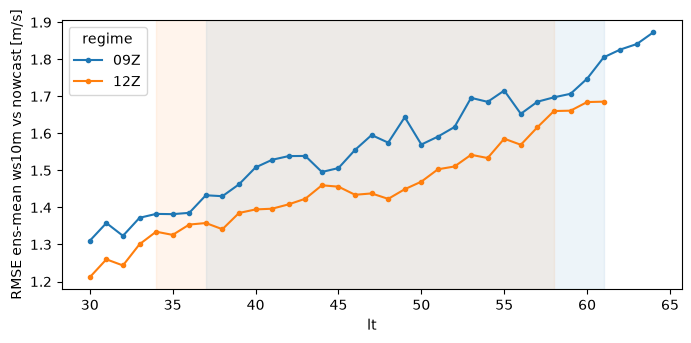

mean RMSE increase per hour of lead time: {'09Z': 0.0166, '12Z': 0.0153}
RMSE averaged over the D+2 window: 12Z (lt 35-58): 1.46 | 09Z (lt 38-61): 1.606


In [12]:
cand = parks.loc[parks["substation_name"].isin(forecast_sids & nowcast_names)]
sample = cand.sort_values("operating_power_max").groupby("bidding_area").tail(1)
sample = sample.loc[sample["bidding_area"].isin(["ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"])]
sample_parks = sample["substation_name"].tolist()
print(ascii(sample[["bidding_area", "substation_name", "operating_power_max"]].values.tolist()))

ws_cols = [f"ws10m_{i:02d}" for i in range(15)]
fc = stream_forecast(["sid", "time_ref", "time", "lt"] + ws_cols, sids=sample_parks, min_lt=30).to_pandas()
fc["ws_mean"] = fc[ws_cols].mean(axis=1)
fc = fc.drop(columns=ws_cols)
stored = [{v: k for k, v in STORED_TO_CANONICAL_NAMES.items()}.get(p, p) for p in sample_parks]
obs = pd.read_parquet(ROOT / "met_nowcast.parquet", columns=["windpark", "wind_speed_10m"],
                      filters=[("windpark", "in", stored)]).reset_index()
obs["windpark"] = obs["windpark"].replace(STORED_TO_CANONICAL_NAMES)
m = fc.merge(obs, left_on=["sid", "time"], right_on=["windpark", "time"])
m["regime"] = np.where(m["time_ref"].dt.hour == 9, "09Z", "12Z")
m["sq"] = (m["ws_mean"] - m["wind_speed_10m"]) ** 2
rmse = m.groupby(["regime", "lt"])["sq"].mean().pow(0.5).unstack(0)
ax = rmse.plot(figsize=(8, 3.5), marker=".")
ax.set_ylabel("RMSE ens-mean ws10m vs nowcast [m/s]"); ax.axvspan(34, 58, alpha=0.08, color="C1"); ax.axvspan(37, 61, alpha=0.08, color="C0")
plt.show()
d = rmse.diff().mean()
print("mean RMSE increase per hour of lead time:", d.round(4).to_dict())
print("RMSE averaged over the D+2 window: 12Z (lt 35-58):", round(rmse.loc[35:58, "12Z"].mean(), 3),
      "| 09Z (lt 38-61):", round(rmse.loc[38:61, "09Z"].mean(), 3))
del fc, obs, m

Caveat: the two regimes also cover different years (12Z: 2020–23, 09Z: 2023–25), so a level difference can come
from MEPS upgrades or weather, not only lead time. The slope within each curve is the cleaner measure.

### Findings (C7)
- Parks used: Bjerk (NO2), Storheia (NO3) and Øyfjell2 (NO4), the largest per zone with both a forecast and a
  nowcast.
- **The error grows by ~0.016 m/s per hour of lead time** in both regimes. The 3 h difference between 12Z and 09Z
  is therefore worth ~0.05 m/s, about 3 % of the ~1.5 m/s error.
- **The regimes' levels differ by more:** 1.46 m/s for 12Z (2020–23) against 1.61 m/s for 09Z (2023–25) over
  their D+2 windows. Lead time explains only about a third of that. The rest comes from the different periods:
  weather, possibly MEPS changes.
- **Consequence:** keep the 12Z issues (all of train is 12Z). Lead time is a minor limitation. The level shift is
  something for the stationarity checks: compare the regimes within val, which contains both.

→ informs **D3, D4**.

## C8 — Evaluation files and the competition's RMSE

In [13]:
for sub in ["evaluation/met_forecast_daily", "evaluation/met_nowcast_daily", "evaluation/wind_power"]:
    fs = [f.name for f in list_files(sub)]
    print(f"{sub}: {len(fs)} files, {fs[0]} … {fs[-1]}")

fc_days = {pd.Timestamp(f.name[12:20]).date() for f in list_files("evaluation/met_forecast_daily")}
window = pd.date_range("2025-09-22", "2025-10-03", freq="D").date
needed_issue_days = [d - pd.Timedelta(days=2) for d in window]
print("\nissue days needed for the WindAI window (targets 22 Sep – 3 Oct):")
print({str(d): d in fc_days for d in needed_issue_days})

evaluation/met_forecast_daily: 115 files, meps_windai_20250529T09Z.csv … meps_windai_20251003T09Z.csv
evaluation/met_nowcast_daily: 123 files, met_nowcast_20250603.parquet … met_nowcast_20251003.parquet
evaluation/wind_power: 128 files, wind_power_per_bidzone_20250601.parquet … wind_power_per_bidzone_20251006.parquet

issue days needed for the WindAI window (targets 22 Sep – 3 Oct):
{'2025-09-20': True, '2025-09-21': True, '2025-09-22': True, '2025-09-23': True, '2025-09-24': True, '2025-09-25': True, '2025-09-26': True, '2025-09-27': True, '2025-09-28': True, '2025-09-29': True, '2025-09-30': True, '2025-10-01': True}


In [14]:
res = pd.read_csv(ROOT / "evaluation/evaluation_results/daily_rmse_results.csv")
print(res.shape, "| teams:", res["team_name"].nunique())
print("dates:", sorted(res["date"].unique()))
summary = res.groupby("team_name")["rmse"].agg(["mean", "count"]).sort_values("mean")
print(summary.head(5))

(96, 3) | teams: 11
dates: ['2025-09-24', '2025-09-25', '2025-09-26', '2025-09-27', '2025-09-28', '2025-10-01', '2025-10-02', '2025-10-03', '2025-10-04', '2025-10-05']
                     mean  count
team_name                       
EquiWindNerds  181.856000     10
Knowit         198.409000     10
WINDCO         208.000000      8
WindSight      208.633333      9
Brew-Booze     210.815556      9


### Findings (C8)
- The eval forecast files (29 May – 3 Oct 2025) contain every issue day needed for targets from 22 Sep to 3 Oct,
  and power runs to 6 Oct.
- **The scored dates don't match the plans.** `daily_rmse_results.csv` (11 teams, 96 rows) scores **24–28 Sep and
  1–5 Oct**, i.e. 10 days with 29–30 Sep missing. F26/S27 say "22 Sep – 3 Oct, excluding 27–28 Sep". Most likely
  `date` is the target day: the last forecast file (3 Oct) is exactly the issue for 5 Oct.
- **The team scores don't match the plans' reference numbers either.** The mean daily RMSE is 181.9 for
  EquiWindNerds, 198.4 for Knowit and 208.0 for WINDCO. The plans cite 207.9 / 217.6 / 216.2 as "averages across
  zones" (Weber, Table 6.3), so those use a different aggregation or a different period.
- **Open question:** check the evaluation window and the competition's RMSE definition against Authen et al.
  (2026) and Weber's Table 6.3 before implementing scoring for the WindAI period. Some teams have only 8–9 days.

→ informs scoring (F26 §3.4) and **D12**.

## C9 — Power timestamp convention
If power at timestamp t is the energy over (t−1, t], it should correlate best with wind averaged over t−1 and t.
Proxy per zone: Σ capacity × power curve(Nowcast wind), using the logistic curve from `synthetic.py`.

In [15]:
nc = pq.read_table(ROOT / "met_nowcast.parquet", columns=["windpark", "wind_speed_10m", "time"],
                   read_dictionary=["windpark"]).to_pandas(ignore_metadata=True)
nc["windpark"] = nc["windpark"].cat.rename_categories(lambda c: STORED_TO_CANONICAL_NAMES.get(c, c))
meta = parks.drop_duplicates("substation_name").set_index("substation_name")[["bidding_area", "operating_power_max"]]
nc = nc.join(meta, on="windpark", how="inner")
nc["proxy"] = nc["operating_power_max"] / (1 + np.exp(-(nc["wind_speed_10m"] - 7.5) / 1.3))
proxy = nc.pivot_table(index="time", columns="bidding_area", values="proxy", aggfunc="sum", observed=True)
proxy.index = proxy.index.tz_localize("UTC")
del nc

variants = {"inst t-1": proxy.shift(1), "avg(t-1,t)": (proxy + proxy.shift(1)) / 2, "inst t": proxy,
            "avg(t,t+1)": (proxy + proxy.shift(-1)) / 2, "inst t+1": proxy.shift(-1)}
corr = pd.DataFrame({name: [power[z].corr(v[z]) for z in ZONES] for name, v in variants.items()}, index=ZONES)
print(corr.round(4))
print("\nbest variant per zone:", corr.idxmax(axis=1).to_dict())

            inst t-1  avg(t-1,t)  inst t  avg(t,t+1)  inst t+1
ELSPOT NO1    0.4810      0.4878  0.4871      0.4912    0.4878
ELSPOT NO2    0.8258      0.8392  0.8441      0.8507    0.8486
ELSPOT NO3    0.8578      0.8681  0.8719      0.8769    0.8754
ELSPOT NO4    0.7535      0.7622  0.7637      0.7685    0.7660

best variant per zone: {'ELSPOT NO1': 'avg(t,t+1)', 'ELSPOT NO2': 'avg(t,t+1)', 'ELSPOT NO3': 'avg(t,t+1)', 'ELSPOT NO4': 'avg(t,t+1)'}


### Findings (C9)
- **In all four zones** the ranking is the same. Wind averaged over **t and t+1** correlates best with power at t,
  wind at t−1 worst. The margins are small (0.003–0.007 in correlation) but consistent.
- **This points to power at timestamp t being the energy of the hour that starts at t**, [t, t+1). F26 §3.1
  assumes the opposite, (t−1, t].
- **Caveats:**
  - the proxy is crude (a logistic power curve on 10 m wind);
  - the result also depends on the nowcast's own time convention (an instant at t, or an average over an hour);
  - the one missing nowcast hour shifts the lag by one row there, which is negligible.
- **Consequence:** using wind at t−1, t and t+1 in the first stage covers both conventions, so the pipeline
  doesn't depend on the answer. The report should state the convention, and check it against the data
  documentation, Weber or the competition paper.

→ informs **D11** (which wind hours enter the first stage).

## Summary

| | Finding | Decision |
|---|---|---|
| C1 | D+2 needs lt 37–61 (09Z) / 34–58 (12Z), ±1 h available for all but **10 truncated 12Z issues**. DST handled (23/25-hour days). | D10: drop the 10 issues. Fix the F26 §2 lead times. |
| C2 | train 1,104 (12Z) / val 357 (half each) / test 337 (09Z). 2 issues cross each boundary. | D2: assign by issue date, purge 2 issues per boundary. |
| C3 | Duplicate names = one park under several EIC codes. Øyfjell1/2 = two phases sharing one code. | D1: **deduplicate by name**. Capacity NO1–NO4: 405.7 / 1,451.3 / 2,120.4 / 1,160.0 MW. |
| C4 | Max CF 0.82–0.98 per zone and year. Never > 1. Hardly any exact zeros at zone level. | Censored normal OK, censoring rarely binds. |
| C5 | All gaps in train. Val complete. One NaN in test. | D10: drop hours without an observation. |
| C6 | Nowcast: one hour missing for every park (2024-08-20 22Z). Data exists before parks start. | D7: weight parks by capacity in operation. |
| C7 | 3 h of lead time ≈ 3 % of the wind error. The regimes' levels differ by ~10 %. | D3: keep 12Z. Check the level shift within val. |
| C8 | **Scored dates 24–28 Sep + 1–5 Oct**, not as in the plans. **Team means don't match the cited reference numbers.** | Open: check against Authen et al. / Weber. |
| C9 | Power at t matches wind over [t, t+1), not (t−1, t]. Weak but consistent. | D11: use wind t−1, t, t+1. State the convention in the report. |

**Open questions:** the WindAI evaluation window and RMSE definition (C8), and the power timestamp convention (C9).